# EDA

In [2]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Exact file name load 
df = pd.read_csv('../data/telco_churn_raw.csv')

# 5 rows display
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# 1. Dataset ki shape (Rows, Columns) seen
print("Dataset Shape:", df.shape)

# 2. all columns of data types aur non-null values check 
df.info()

Dataset Shape: (7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling

In [4]:
# 1. Drop customerID column safely if present in DataFrame
if 'customerID' in df.columns:
    df = df.drop(columns=['customerID'])

# 2. Replace empty string spaces with NaN and convert column to numeric float
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].replace(" ", np.nan))

# 3. Check exact count of missing values in TotalCharges
print("Missing values in TotalCharges:", df['TotalCharges'].isnull().sum())

# 4. Impute missing values using the median value (without inplace warning)
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

# 5. Map the target column 'Churn' to binary numeric values (0 and 1)
if df['Churn'].dtype == 'object':
    df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})

# 6. Verify cleaned dataset dimensions and target class ratio
print("Cleaned Dataset Shape:", df.shape)
print("\nTarget Class Distribution:")
print(df['Churn'].value_counts(normalize=True))

Missing values in TotalCharges: 11
Cleaned Dataset Shape: (7043, 20)

Target Class Distribution:
Churn
0    0.73463
1    0.26537
Name: proportion, dtype: float64


In [5]:
# Save cleaned dataframe into data folder
df.to_csv('../data/telco_churn_cleaned.csv', index=False)
print("Dataset saved successfully!")

Dataset saved successfully!


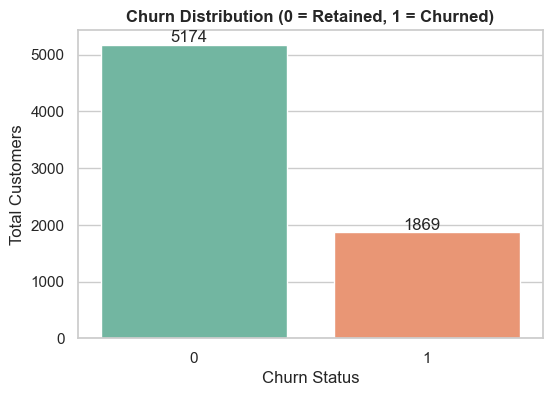

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual theme
sns.set_theme(style="whitegrid")

# Create a count plot for the target variable (Churn)
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='Churn', data=df, palette='Set2')

# Add title and labels
plt.title('Churn Distribution (0 = Retained, 1 = Churned)', fontsize=12, fontweight='bold')
plt.xlabel('Churn Status')
plt.ylabel('Total Customers')

# Display exact counts on top of bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + 0.3, p.get_height() + 50))

plt.show()

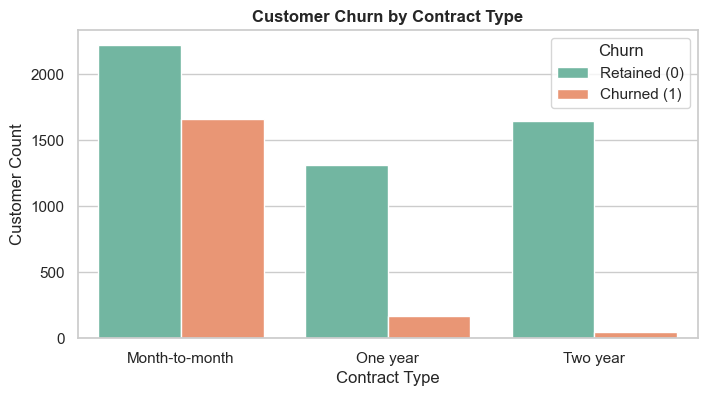

In [7]:
# Visualize churn rate across different contract types
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='Contract', hue='Churn', palette='Set2')

# Add labels and formatting
plt.title('Customer Churn by Contract Type', fontsize=12, fontweight='bold')
plt.xlabel('Contract Type')
plt.ylabel('Customer Count')
plt.legend(title='Churn', labels=['Retained (0)', 'Churned (1)'])

plt.show()

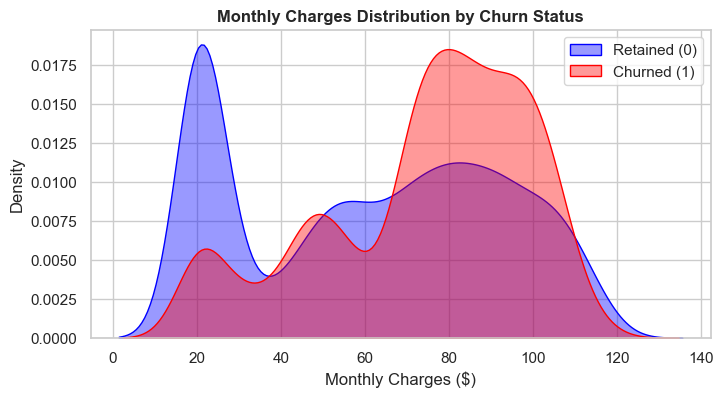

In [8]:
# Visualize the distribution of Monthly Charges across Churn classes
plt.figure(figsize=(8, 4))
sns.kdeplot(data=df[df['Churn'] == 0]['MonthlyCharges'], label='Retained (0)', fill=True, color='blue', alpha=0.4)
sns.kdeplot(data=df[df['Churn'] == 1]['MonthlyCharges'], label='Churned (1)', fill=True, color='red', alpha=0.4)

# Set labels and title
plt.title('Monthly Charges Distribution by Churn Status', fontsize=12, fontweight='bold')
plt.xlabel('Monthly Charges ($)')
plt.ylabel('Density')
plt.legend()

plt.show()

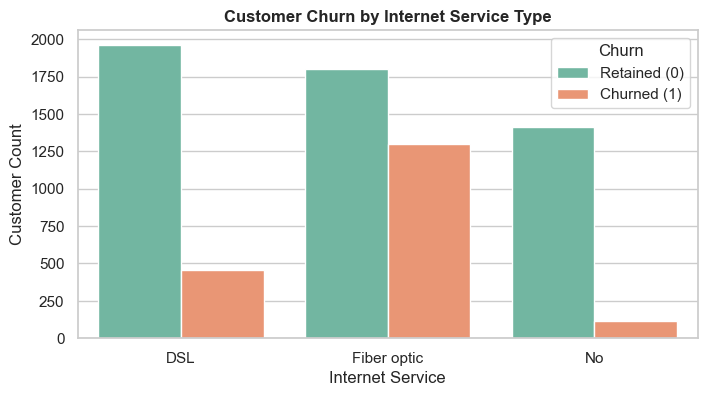

In [9]:
# Visualize churn rate across different internet service types
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='InternetService', hue='Churn', palette='Set2')

# Add labels and formatting
plt.title('Customer Churn by Internet Service Type', fontsize=12, fontweight='bold')
plt.xlabel('Internet Service')
plt.ylabel('Customer Count')
plt.legend(title='Churn', labels=['Retained (0)', 'Churned (1)'])

plt.show()

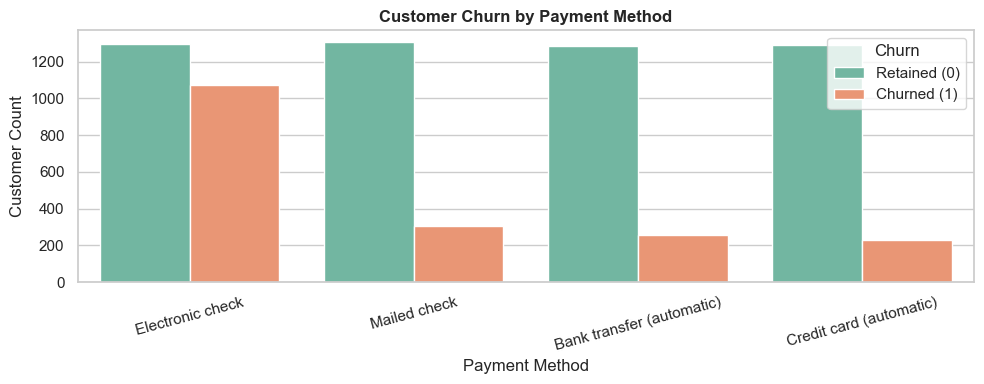

In [10]:
# Visualize churn rate across different payment methods
plt.figure(figsize=(10, 4))
sns.countplot(data=df, x='PaymentMethod', hue='Churn', palette='Set2')

# Add labels and formatting
plt.title('Customer Churn by Payment Method', fontsize=12, fontweight='bold')
plt.xlabel('Payment Method')
plt.ylabel('Customer Count')
plt.xticks(rotation=15)
plt.legend(title='Churn', labels=['Retained (0)', 'Churned (1)'])

plt.tight_layout()
plt.show()

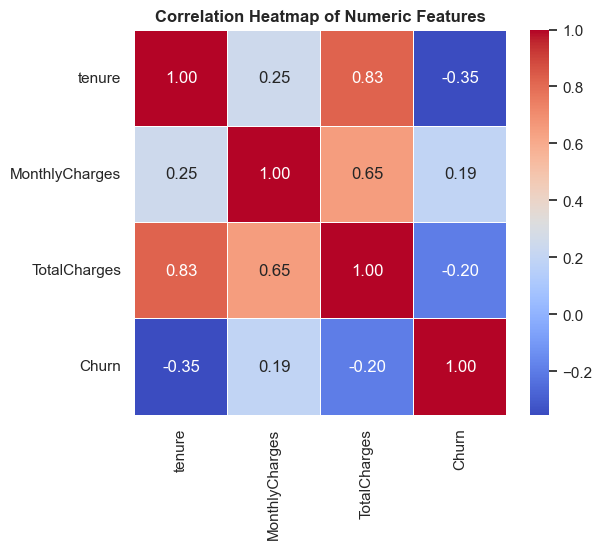

In [11]:
# Calculate correlation matrix for numeric columns
numeric_features = ['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']
corr_matrix = df[numeric_features].corr()

# Plot the correlation heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)

# Add title
plt.title('Correlation Heatmap of Numeric Features', fontsize=12, fontweight='bold')
plt.show()

# feature engineering

In [13]:
# Convert categorical variables into dummy/indicator numerical variables
# drop_first=True avoids the dummy variable trap (multicollinearity)
df_encoded = pd.get_dummies(df, drop_first=True)

# Display updated shape and the first 3 rows of processed data
print("Shape before encoding:", df.shape)
print("Shape after encoding:", df_encoded.shape)
df_encoded.head(3)

Shape before encoding: (7043, 20)
Shape after encoding: (7043, 31)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,False,True,False,False,True,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,0,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,1,True,False,False,True,False,...,False,False,False,False,False,False,True,False,False,True


In [14]:
# Separate features (X) and target variable (y)
X = df_encoded.drop('Churn', axis=1)
y = df_encoded['Churn']

# Verify feature matrix and target vector shapes
print("Features shape (X):", X.shape)
print("Target shape (y):", y.shape)

Features shape (X): (7043, 30)
Target shape (y): (7043,)


In [15]:
from sklearn.model_selection import train_test_split

# Split dataset into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Print split dataset dimensions
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (5634, 30)
X_test shape: (1409, 30)
y_train shape: (5634,)
y_test shape: (1409,)


# Feature Scaling (Normalization)

In [17]:
from sklearn.preprocessing import StandardScaler

# Initialize the StandardScaler
scaler = StandardScaler()

# Define the numerical columns that require scaling
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

# Fit scaler on training data and transform both train and test sets
X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

# Display the first 3 rows of scaled training features
print("Scaling completed successfully!")
X_train[numeric_cols].head(3)

Scaling completed successfully!


,tenure,MonthlyCharges,TotalCharges
3738,0.102371,-0.521976,-0.263289
3151,-0.711743,0.337478,-0.504814
4860,-0.793155,-0.809013,-0.751213


# Phase 4: Model Building and Baseline Training
In this phase, we train baseline machine learning models to predict customer churn.

In [18]:
# ==========================================
# STEP 4.1: LOGISTIC REGRESSION (BASELINE)
# ==========================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# 1. Initialize the baseline Logistic Regression model
log_reg = LogisticRegression(random_state=42)

# 2. Train the model on the scaled training dataset
log_reg.fit(X_train, y_train)

# 3. Predict churn status on the unseen testing set
y_pred_log = log_reg.predict(X_test)

# 4. Display model accuracy and detailed evaluation metrics
print("Logistic Regression Accuracy:", round(accuracy_score(y_test, y_pred_log), 4))
print("\nClassification Report:\n", classification_report(y_test, y_pred_log))

Logistic Regression Accuracy: 0.8055

Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



## Step 4.2: Random Forest Classifier (Baseline Model)
Training an ensemble tree-based model to capture non-linear feature relationships.

In [19]:
# ==========================================
# STEP 4.2: RANDOM FOREST CLASSIFIER
# ==========================================

from sklearn.ensemble import RandomForestClassifier

# 1. Initialize the Random Forest model
rf_model = RandomForestClassifier(random_state=42)

# 2. Train the model on the scaled training dataset
rf_model.fit(X_train, y_train)

# 3. Predict churn status on the testing set
y_pred_rf = rf_model.predict(X_test)

# 4. Display model performance metrics
print("Random Forest Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.785

Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035
           1       0.62      0.49      0.55       374

    accuracy                           0.78      1409
   macro avg       0.72      0.69      0.70      1409
weighted avg       0.77      0.78      0.78      1409



# Phase 5: Handling Class Imbalance for Higher Recall
Tuning models with balanced class weights to maximize churn detection recall.

In [20]:
# ==========================================
# STEP 5.1: BALANCED LOGISTIC REGRESSION
# ==========================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

# 1. Initialize Logistic Regression with class_weight='balanced'
log_reg_balanced = LogisticRegression(class_weight='balanced', random_state=42)

# 2. Train the model on scaled training features
log_reg_balanced.fit(X_train, y_train)

# 3. Predict on unseen test set
y_pred_balanced = log_reg_balanced.predict(X_test)

# 4. Display results
print("Accuracy:", round(accuracy_score(y_test, y_pred_balanced), 4))
print("\nClassification Report (High Recall Focus):\n")
print(classification_report(y_test, y_pred_balanced))

Accuracy: 0.7388

Classification Report (High Recall Focus):

              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.51      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



## Step 5.2: Confusion Matrix Visualization (Balanced Logistic Regression)
Visualizing True Positives (captured churners) versus False Negatives (missed churners).

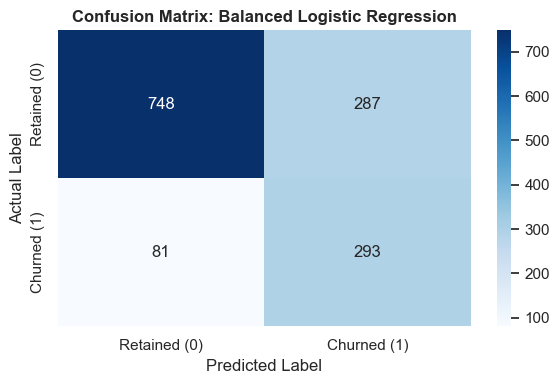

In [21]:
# ==========================================
# STEP 5.2: CONFUSION MATRIX HEATMAP
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred_balanced)

# Plot confusion matrix as a heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Retained (0)', 'Churned (1)'],
    yticklabels=['Retained (0)', 'Churned (1)']
)

plt.title('Confusion Matrix: Balanced Logistic Regression', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.show()

# Phase 6: Final Model Comparison and Summary
Consolidating evaluation metrics across baseline and balanced models to identify the optimal model for production.

In [22]:
# ==========================================
# STEP 6.1: MODEL COMPARISON DATAFRAME
# ==========================================

import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Dictionary of trained models and predictions
model_dict = {
    "Logistic Regression (Baseline)": (log_reg.predict(X_test), log_reg.predict_proba(X_test)[:, 1]),
    "Random Forest (Baseline)": (rf_model.predict(X_test), rf_model.predict_proba(X_test)[:, 1]),
    "Logistic Regression (Balanced)": (y_pred_balanced, log_reg_balanced.predict_proba(X_test)[:, 1])
}

# Compile performance metrics into a structured summary table
results = []
for model_name, (preds, probs) in model_dict.items():
    results.append({
        "Model Name": model_name,
        "Accuracy": round(accuracy_score(y_test, preds), 4),
        "Precision (Churn)": round(precision_score(y_test, preds), 4),
        "Recall (Churn)": round(recall_score(y_test, preds), 4),
        "F1-Score": round(f1_score(y_test, preds), 4),
        "ROC-AUC": round(roc_auc_score(y_test, probs), 4)
    })

# Convert list to DataFrame and display
comparison_df = pd.DataFrame(results)
comparison_df

,Model Name,Accuracy,Precision (Churn),Recall (Churn),F1-Score,ROC-AUC
0,Logistic Regression (Baseline),0.8055,0.6572,0.5588,0.6040,0.8421
1,Random Forest (Baseline),0.7850,0.6187,0.4947,0.5498,0.8257
2,Logistic Regression (Balanced),0.7388,0.5052,0.7834,0.6143,0.8417


# Phase 7: Model Serialization and Export
Saving the trained balanced model, standard scaler, and feature columns for deployment in a Streamlit application.

In [23]:
# ==========================================
# STEP 7.1: SAVE ARTIFACTS USING JOBLIB
# ==========================================

import joblib

# 1. Save the best model (Balanced Logistic Regression)
joblib.dump(log_reg_balanced, 'churn_model.pkl')

# 2. Save the fitted StandardScaler
joblib.dump(scaler, 'scaler.pkl')

# 3. Save feature column names to maintain exact alignment during deployment
joblib.dump(list(X.columns), 'features_list.pkl')

print("All artifacts (churn_model.pkl, scaler.pkl, features_list.pkl) saved successfully!")

All artifacts (churn_model.pkl, scaler.pkl, features_list.pkl) saved successfully!
